<img src="https://github.com/Ch3ddarr/DSB-Unit-03/blob/main/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Regression Metrics

> All models are wrong, but some are useful.
>
> - <cite>George EP Box</cite>
---

### About
An introduction to Regression Metrics: what they are, how they work, and how use them to assess regression models in `scikit-learn`.

### Learning Objectives
- Describe the principles of regression metrics.
- Define common metrics including error measures (MAE, MSE, RMSE), R2, Adj R2 and others.
- Apply regression metrics to assess OLS models.


### Notebook Guide

- Metric #1 (Warmup): Euclidean Distance
- Prologue: Let's fit a model!
- Metric #2: Sum Squared Error (SSE)
- Metric #3: Mean Squared Error (MSE)
- Metric #4: The Coefficient of Determination (R2)
- Metric #5: Mean Absolute Deviation
- Conclusion and Takeaways

# Imports
As always... come back to this cell when you want to add more imports!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Metric #1 (Warmup): Euclidean Distance

In [2]:
y = [4, 18, 9, 2, 7, 5]
y_hat = [3, 15, 8, 1, 8, 12]

In [8]:
# Compute the distance via a listcomp!
np.sqrt(sum([(yi - y_hati)**2 for yi, y_hati in zip(y,y_hat)]))

np.float64(7.874007874011811)

In [9]:
# Compute the distance via numpy!
y = np.array(y)
y_hat = np.array(y_hat)

np.sqrt(np.sum((y-y_hat)**2))

np.float64(7.874007874011811)

# Prologue: Let's fit a model!

In [13]:
# Read in ad data
ads = pd.read_csv("https://raw.githubusercontent.com/Ch3ddarr/DSB-Unit-03/refs/heads/main/data/Advertising.csv")


In [14]:
ads.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [15]:
ads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [19]:
# (THREAD) Drop unnamed col
cp_ads = ads.drop(columns='Unnamed: 0')
cp_ads.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


### Think
Look at this data. What do you think is a good question to ask that we might model?

### Quick EDA
Let's poke around this data to see what we're working with.

In [20]:
cp_ads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [30]:
cp_ads.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


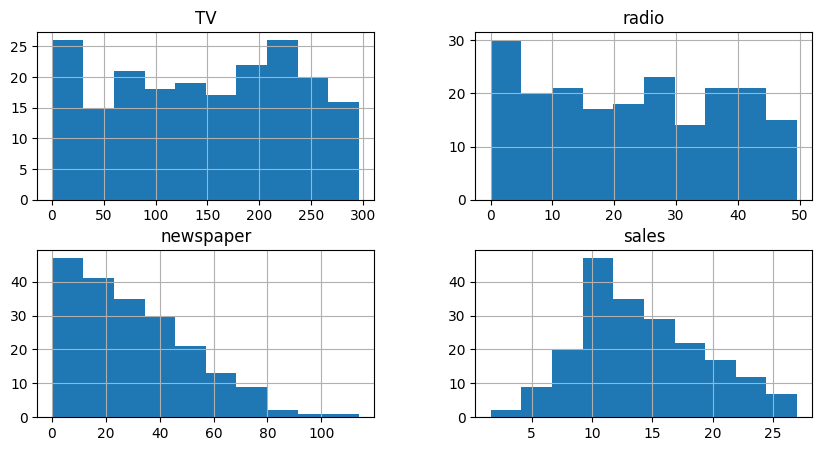

In [32]:
cp_ads.hist(figsize=(10,5));

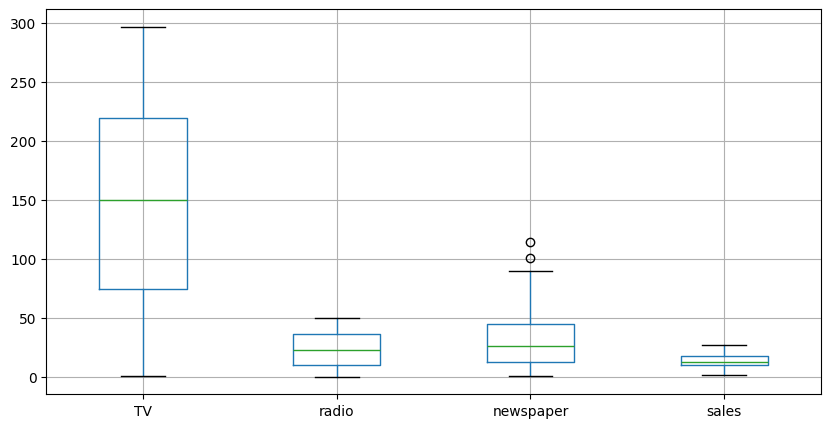

In [29]:
cp_ads.boxplot(figsize=(10,5));

In [33]:
# Create the design matrix (X) and response vector (y)
X = cp_ads.drop(columns='sales')
y = cp_ads.sales

In [34]:
from re import L
# Fit a linear regression model
lm = LinearRegression()
lm.fit(X,y)

LinearRegression()

In [35]:
# Create a prediction vector y_hat
y_hat = lm.predict(X)

In [36]:
# using coef_ allows us to see the coefficients of the model, which represent
# the change in the response variable(sales) for a one_unit change in each
# predictor variable (TV, radio, newspaper), holding all other predictors constant.
lm.coef_

array([ 0.04576465,  0.18853002, -0.00103749])

In [ ]:
# Interpret one of the slopes for me!


# Metric #2: Sum Squared Error (SSE)


In [37]:
# Compute the SSE using numpy
sse = np.sum((y-y_hat)**2)
sse

np.float64(556.8252629021872)

# Metric #3: Mean Squared Error (MSE)


In [38]:
# Compute the MSE using numpy
mse = np.mean((y-y_hat)**2)
mse

np.float64(2.784126314510936)

In [39]:
# Compute the MSE using sklearn!
metrics.mean_squared_error(y,y_hat)

2.784126314510936

### Metric #3.5: The Root Mean Squared Error (RMSE)


In [40]:
# Compute the RMSE! Does it make sense?

# the value of the RMSE is 1.668, which means that on average, our predictions
# are off by about 1.668 units of sales. This is a more interpretable metric
# than the MSE, as it is in the
np.sqrt(metrics.mean_squared_error(y,y_hat))

np.float64(1.6685701407225697)

# Metric #4: The Coefficient of Determination ($R^2$)


In [41]:
# Let's compute it "by hand"
sse = np.sum((y-y_hat)**2)
ssto = np.sum((y-np.mean(y))**2)
1 - sse /ssto

np.float64(0.8972106381789522)

In [42]:
# Can also compute directly via sklearn!
lm.score(X,y)

0.8972106381789522

In [44]:
# ...and via metrics
metrics.r2_score(y,y_hat)

0.8972106381789522

In [45]:
# Let's compute the SSE, MSE, RMSE of the null model.
m = y.mean()
sse = np.sum((y-m)**2)
mse = np.mean((y-m)**2)
rmse = np.sqrt(mse)

print(f"SSE = {sse}")
print(f"MSE = {mse}")
print(f"RMSE = {rmse}")

SSE = 5417.14875
MSE = 27.085743750000002
RMSE = 5.204396578855228


In [46]:
# Compare to our OLS model:
sse = np.sum((y-y_hat)**2)
mse = metrics.mean_squared_error(y,y_hat)
rmse = np.sqrt(mse)

print(f"SSE = {sse}")
print(f"MSE = {mse}")
print(f"RMSE = {rmse}")

SSE = 556.8252629021872
MSE = 2.784126314510936
RMSE = 1.6685701407225697


# Metric #5: Mean Absolute Deviation


In [47]:
# Compute!
metrics.mean_absolute_error(y,y_hat)

1.252011229687068

# Conclusion and Takeaways
In this lesson, we:

- Learned what distance metrics are (mathematically) and how they might apply to us
- Learned several regression error metrics, and why/when we might use them
- Explored the `sklearn.metrics` submodule and poked around all the different metrics it provides